In [1]:
import io
import sys
import tqdm
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from transformers import AutoTokenizer
import matplotlib.pyplot as plt

# Add your project src directory
sys.path.append(r"/home/susanket/esri-vlm/src")
from model import CLIP, build_model
from main import CLIPLightningModule

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

/data/susanket/conda/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


In [2]:
CKPT_PATH = "/home/susanket/esri-vlm/lightning_logs/version_0/checkpoints/epoch=2-step=8577.ckpt"  # Update path

ckpt = torch.load(CKPT_PATH, map_location=device, weights_only=False)

if "hyper_parameters" in ckpt:
    # Clean up non-serializable or unnecessary hyperparameters
    for hp_key in ["eval_downstream", "air_temp_data_path", "election_data_path", "_instantiator"]:
        ckpt["hyper_parameters"].pop(hp_key, None)

    lightning_model = CLIPLightningModule(**ckpt["hyper_parameters"]).to(device)
    lightning_model.load_state_dict(ckpt["state_dict"])
    lightning_model.eval()
    model = lightning_model.model
    tokenizer = lightning_model.tokenizer
else:
    model = build_model(ckpt["state_dict"]).to(device)
    tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-Embedding-0.6B", padding_side="left")

model = model.to(device)
model.eval()

# Handle DINOv2 backbone if feature extraction is required
dino_backbone = None
if getattr(model.visual, "precomputed", False):
    from model import DINOV2_REPO
    try:
        dino_backbone = torch.hub.load(DINOV2_REPO, model.visual.model_name, trust_repo=True)
    except TypeError:
        dino_backbone = torch.hub.load(DINOV2_REPO, model.visual.model_name)
    dino_backbone.eval().to(device)

print("Model successfully loaded!")

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 6549.28it/s]
Using cache found in /home/susanket/.cache/torch/hub/facebookresearch_dinov2_main
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/susanket/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Model successfully loaded!


In [3]:
PARQUET_PATH = "/data/susanket/vlm/images3/image-00.parquet"  # Update path
IMAGE_COLUMN = "image_bytes"  # Column name containing raw image bytes or dict with 'bytes'

df = pd.read_parquet(PARQUET_PATH).sample(10_000)
print(f"Loaded {len(df)} samples from {PARQUET_PATH}")

image_transform = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def decode_and_transform(raw_image_data):
    """Helper to handle bytes directly or HuggingFace Datasets dict format."""
    if isinstance(raw_image_data, dict) and "bytes" in raw_image_data:
        raw_bytes = raw_image_data["bytes"]
    else:
        raw_bytes = raw_image_data

    try:
        img = Image.open(io.BytesIO(raw_bytes)).convert("RGB")
    except Exception:
        img = Image.new("RGB", (224, 224))
    return img

raw_pil_images = [decode_and_transform(row[IMAGE_COLUMN]) for _, row in tqdm.tqdm(df.iterrows())]
tensor_images = torch.stack([image_transform(img) for img in tqdm.tqdm(raw_pil_images)])

Loaded 10000 samples from /data/susanket/vlm/images3/image-00.parquet


10000it [00:06, 1573.72it/s]
100%|██████████| 10000/10000 [08:33<00:00, 19.47it/s]


In [4]:
BATCH_SIZE = 256
all_img_embeddings = []

with torch.no_grad():
    for i in range(0, len(tensor_images), BATCH_SIZE):
        batch = tensor_images[i : i + BATCH_SIZE].to(device)
        
        if dino_backbone is not None:
            feats = dino_backbone.forward_features(batch)
            batch = torch.cat([
                feats["x_norm_clstoken"].unsqueeze(1),
                feats["x_norm_patchtokens"]
            ], dim=1)

        embeddings = model.encode_image(batch)
        embeddings = F.normalize(embeddings, dim=-1)
        all_img_embeddings.append(embeddings.cpu().numpy())

image_embeddings = np.concatenate(all_img_embeddings, axis=0)
print(f"Computed embeddings matrix shape: {image_embeddings.shape}")

Computed embeddings matrix shape: (10000, 256)


In [5]:
QUERIES = [
    "residential buildings",
    "solar panel farm",
    "commercial airport runway",
    "dense forest and river",
    "bseball fields",
    "baseball fields",
    "sports fields"
]

with torch.no_grad():
    enc = tokenizer(
        QUERIES,
        padding=True,
        truncation=True,
        max_length=model.transformer.context_length,
        return_tensors="pt",
    )
    tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
    
    text_embeddings = model.encode_text(tokens)
    text_embeddings = F.normalize(text_embeddings, dim=-1).cpu().numpy()

# Cosine similarity matrix: (num_queries, num_images)
similarity_matrix = text_embeddings @ image_embeddings.T

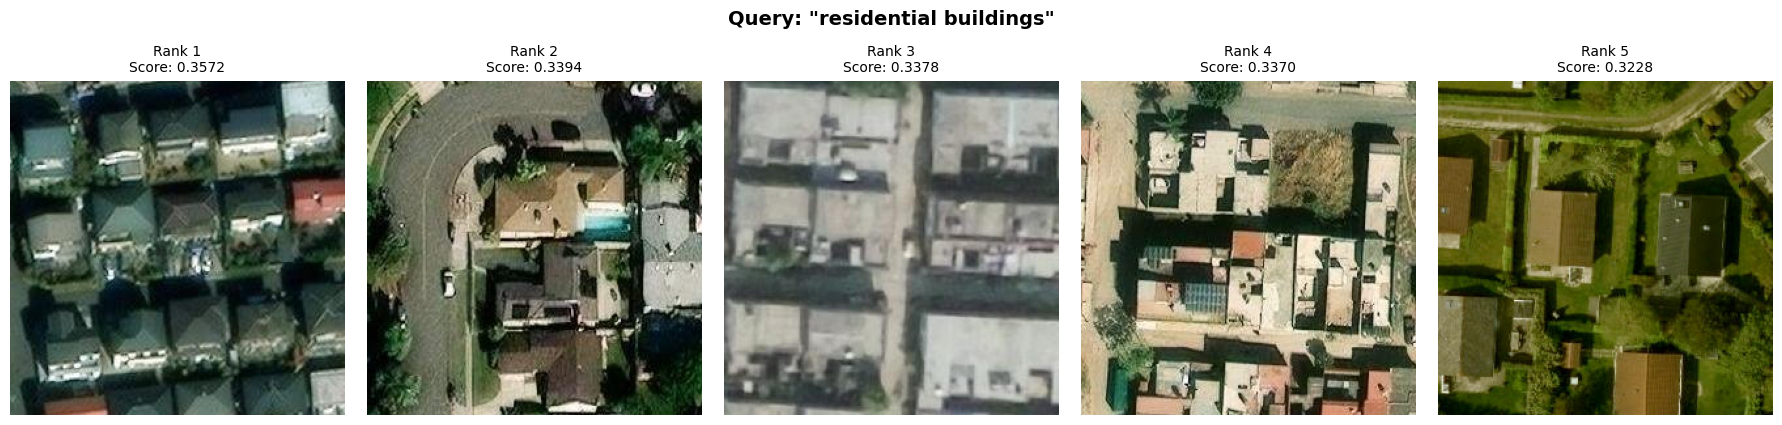

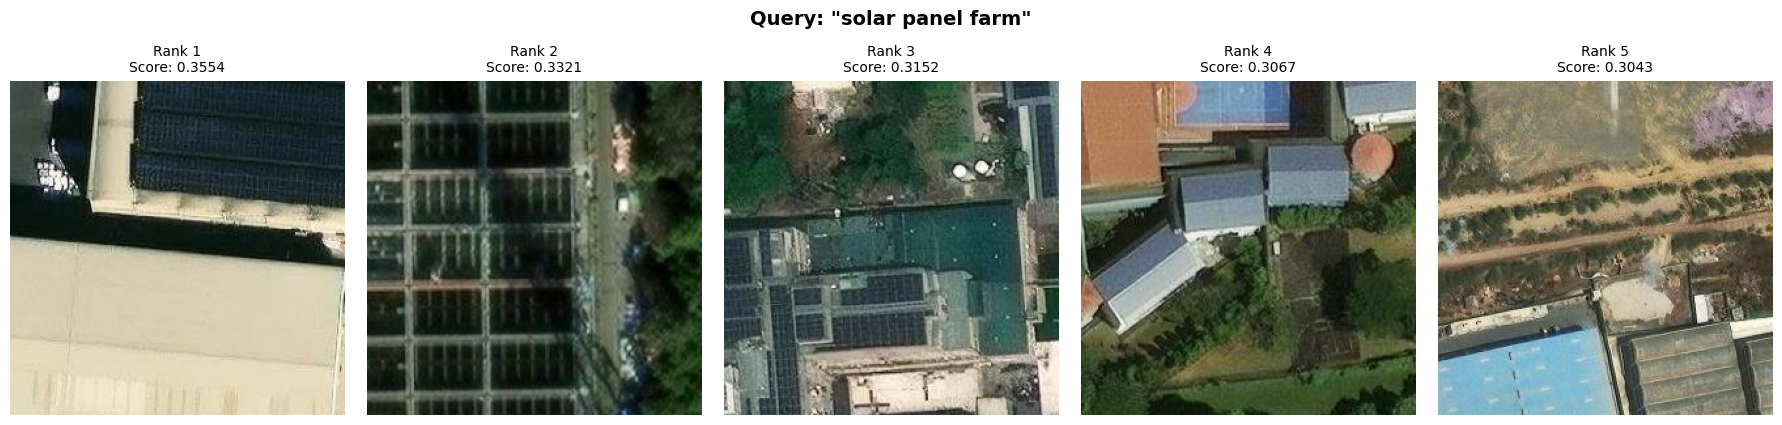

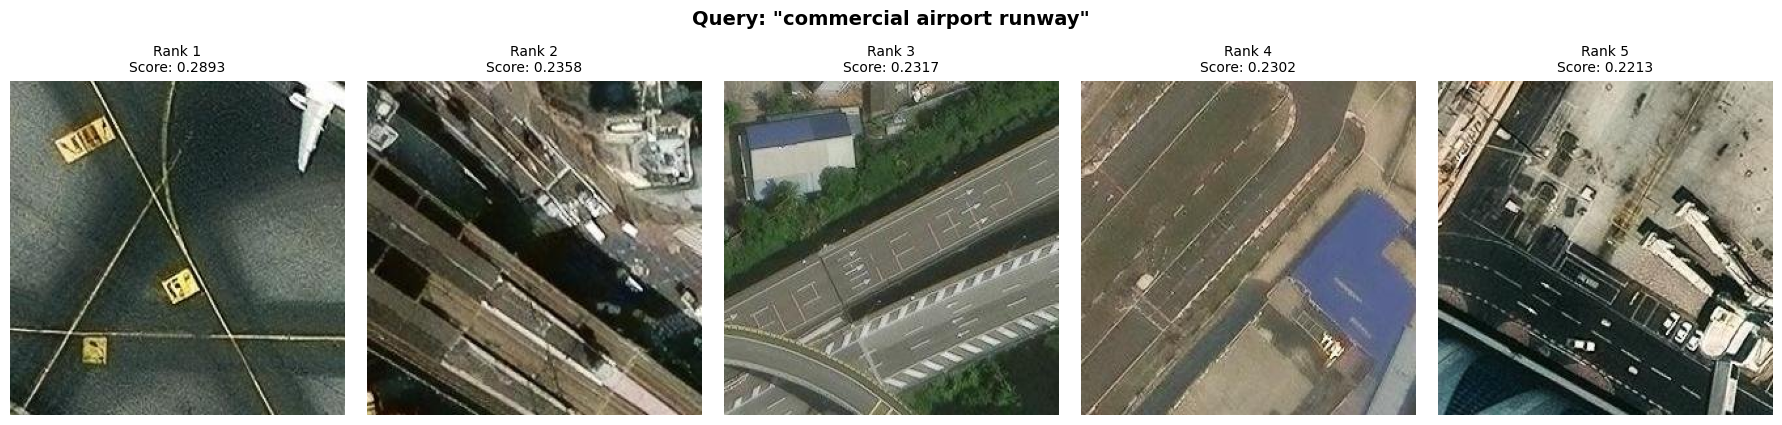

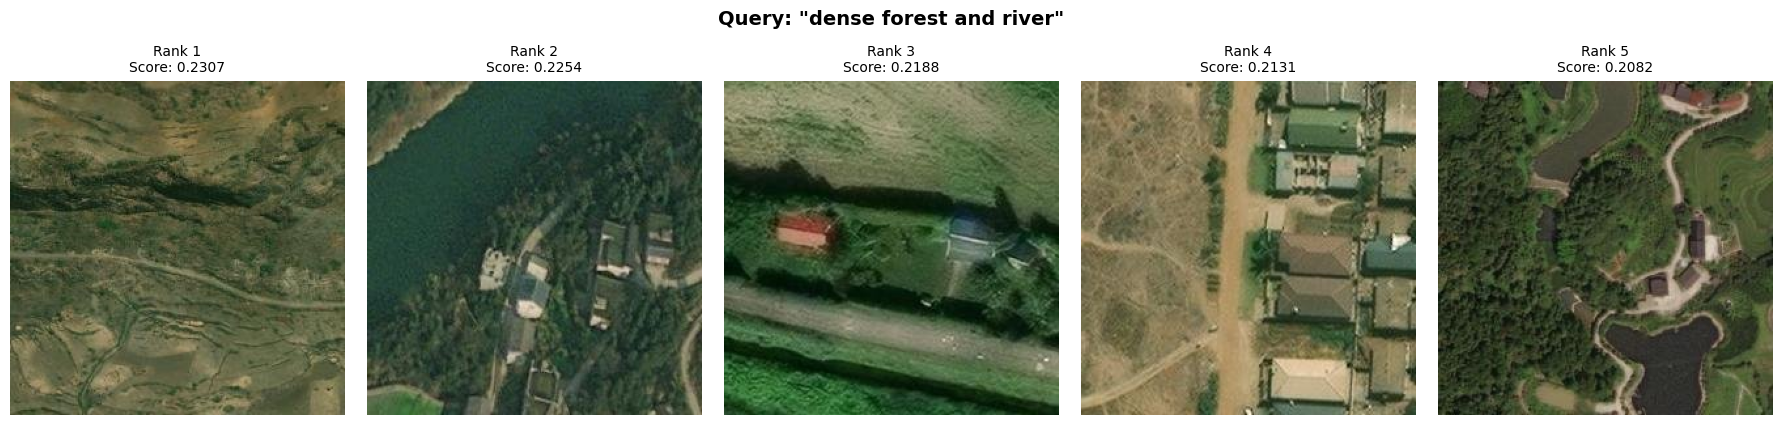

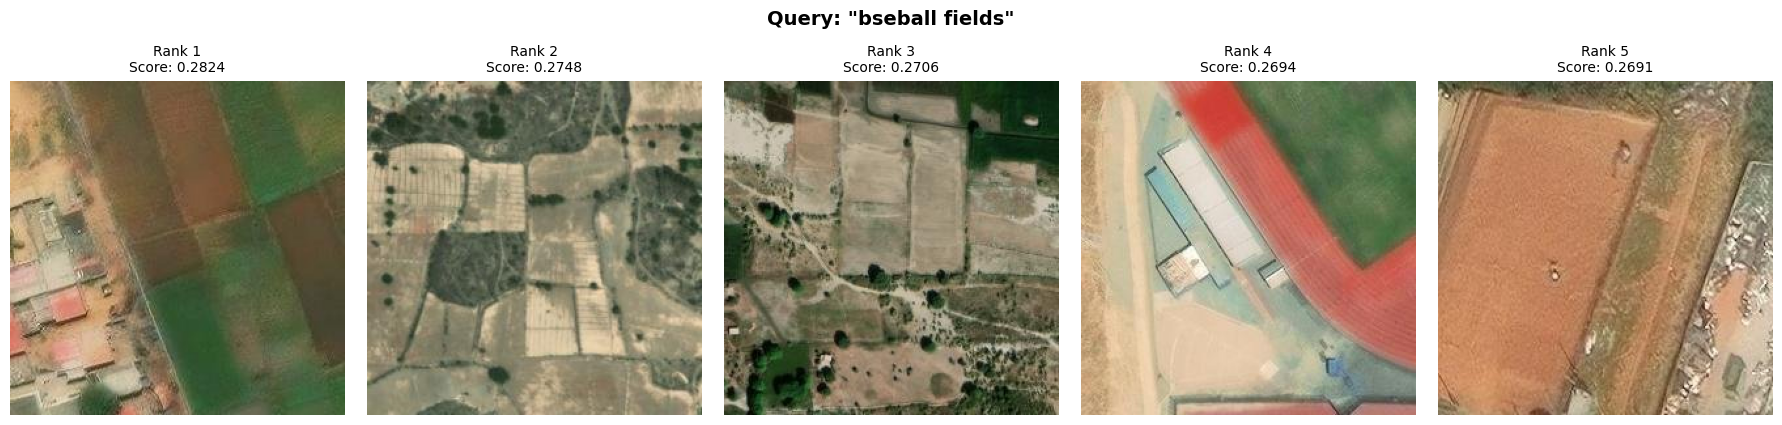

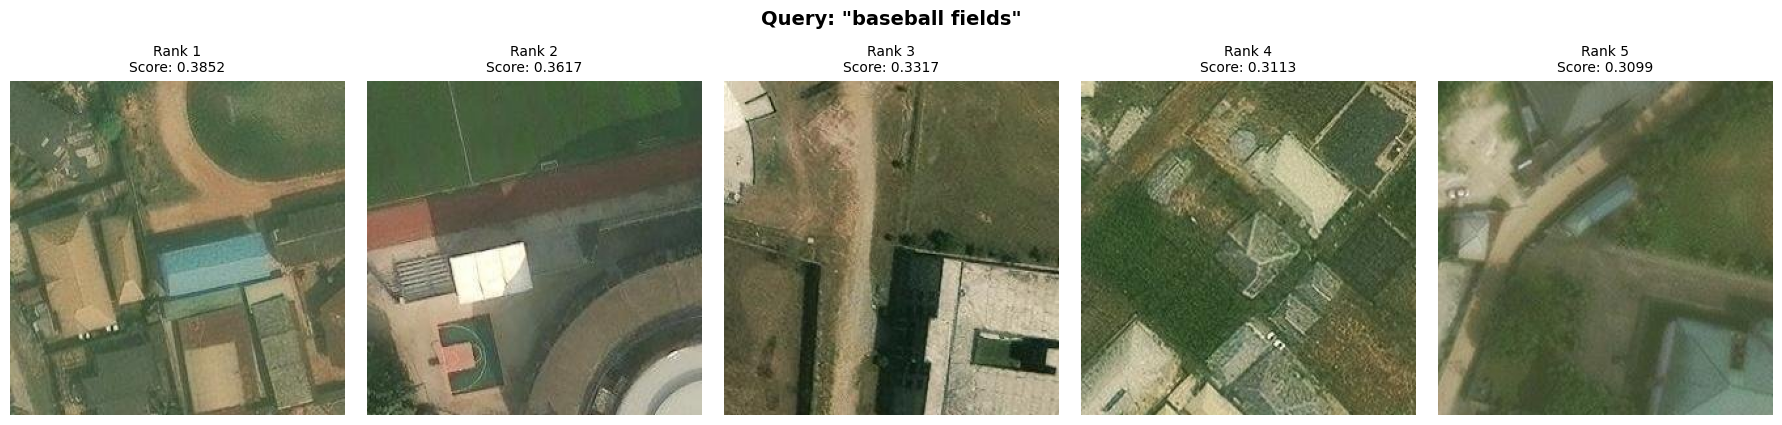

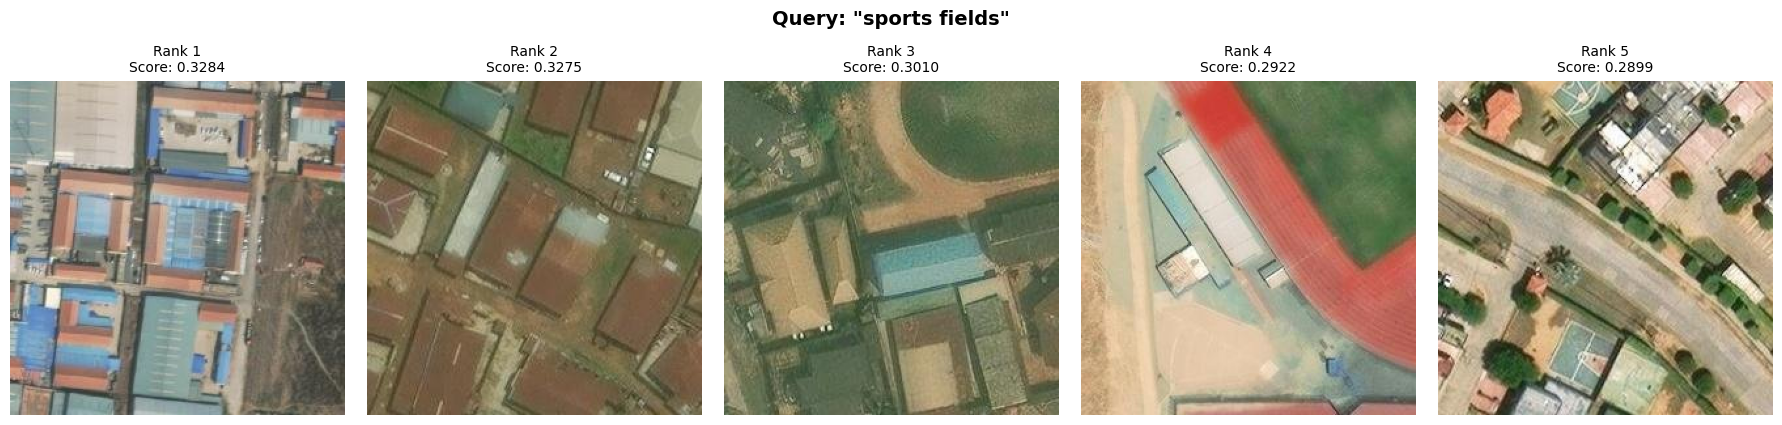

In [6]:
TOP_K = 5

for q_idx, query in enumerate(QUERIES):
    scores = similarity_matrix[q_idx]
    top_k_indices = np.argsort(-scores)[:TOP_K]

    fig, axes = plt.subplots(1, TOP_K, figsize=(18, 4))
    fig.suptitle(f'Query: "{query}"', fontsize=14, fontweight="bold", y=1.05)

    for idx, img_idx in enumerate(top_k_indices):
        score = scores[img_idx]
        ax = axes[idx] if TOP_K > 1 else axes
        
        ax.imshow(raw_pil_images[img_idx])
        ax.set_title(f"Rank {idx+1}\nScore: {score:.4f}", fontsize=10)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [7]:
import math

def plot_topk(query, topk = 100):
    with torch.no_grad():
        enc = tokenizer(
            [query],
            padding=True,
            truncation=True,
            max_length=model.transformer.context_length,
            return_tensors="pt",
        )
        tokens = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
        query_emb = model.encode_text(tokens)
        query_emb = F.normalize(query_emb, dim=-1).cpu().numpy()

    # 3. Compute cosine similarity across ALL dataset images
    all_scores = (query_emb @ image_embeddings.T).squeeze(0)  # Shape: (num_images,)

    # 4. Get indices of top TOP_K highest scores
    top_indices = np.argsort(-all_scores)[:topk]
    top_scores = all_scores[top_indices]

    # 5. Plot 10x10 top-100 collage
    fig, axes = plt.subplots(10, 10, figsize=(20, 2 * 10))
    fig.suptitle(f'Top {topk} Retrieved Images for Query:\n"{query}"', fontsize=16, fontweight="bold", y=1.02)

    axes = axes.flatten()

    for i in range(len(axes)):
        ax = axes[i]
        if i < topk:
            img_idx = top_indices[i]
            score = top_scores[i]
            
            ax.imshow(raw_pil_images[img_idx])
            ax.set_title(f"#{i+1} | {score:.3f}", fontsize=8, pad=3)
            ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

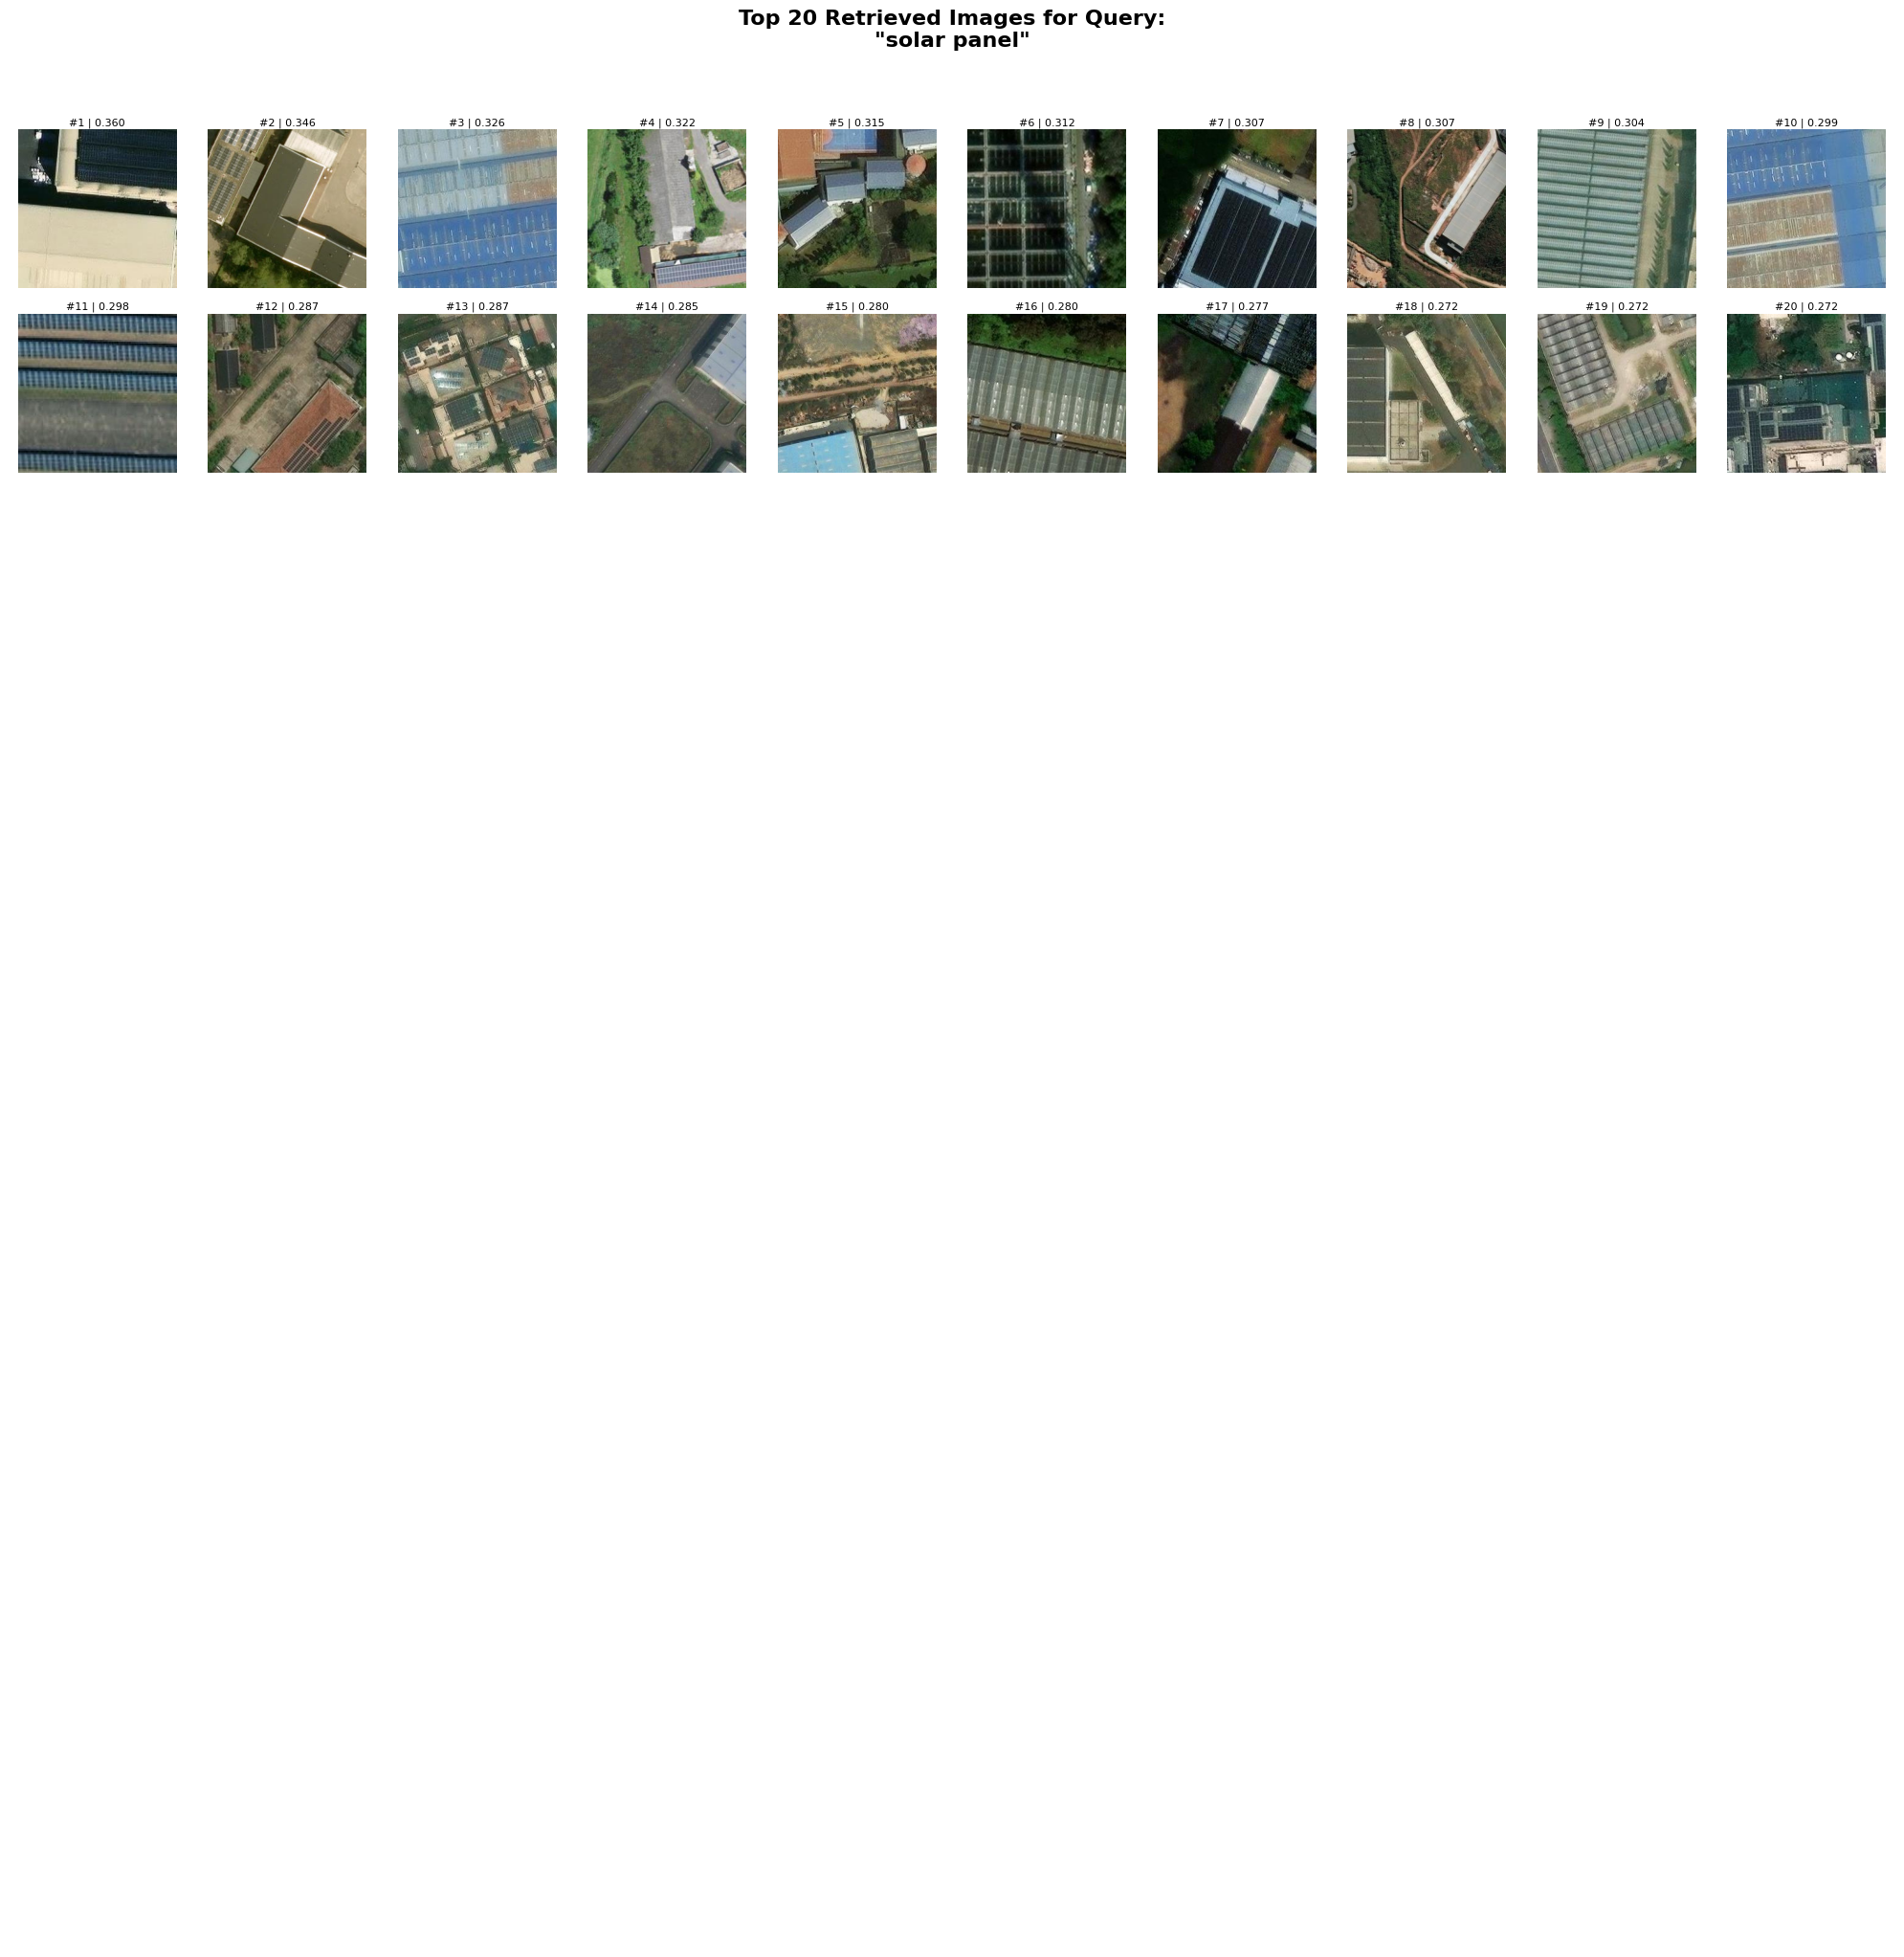

In [8]:
plot_topk("solar panel", topk = 20)

---